# Track B — Empirical Baseline: IBL Mouse Behaviour in Biased Blocks
**Author:** Joshua Koilpillai (2024101128) · **Project:** How does an uncued, inferred prior enter the decision process? (INCM)

Week 2 deliverable (plan §4, Track B): empirical **psychometric** and **chronometric** curves, the diagnostic
**Conditional Bias Function (CBF)**, and a **heterogeneity profile** for the 10 IBL mice built in Week 1, plus a
validation of the tools on synthetic mock data and on Track A's simulator (§3.1 contract).

**Conventions** (Week 1): `prior = +1` right-biased block (P(left stimulus) = 0.2); `choice = +1` Right response;
`contrast` signed (+ = right); **`rt = response_times − stimOn`** (stimulus onset to wheel-threshold crossing), kept in [0.1, 2.5] s.

> **RT definition (changed after the Week 2 audit).** The Week 1 cohort used `firstMovement − stimOn`. That value is ≤ 0.1 s on
> ~45% of responded trials (anticipatory wheel movement), so the 0.1 s filter discarded nearly half of the data and — as §4.2
> shows — those trials carry more of the prior, which distorted the CBF. The contract `rt` is now the response time; the
> first-movement time is kept as `rt_firstmove` for sensitivity analyses. Same 10 mice, many more trials.

Everything below is **descriptive**: the C1 adjudication between M1/M2/M3 (ΔBIC + model-predicted CBFs) happens in Week 3.

In [1]:
import os, sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

from src.empirical import *
from src.empirical.cbf import compute_cbf, DEFAULT_MIN_ABS_SLOPE
from src.visualization import *
from src.models.simulator import simulate_ddm

N_BOOT = 500          # bootstrap resamples (CBF slopes, prior shift)
TAB = ROOT / "results" / "empirical"; FIG = ROOT / "results" / "figures" / "empirical"
TAB.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams["figure.dpi"] = 110

df = pd.read_parquet(ROOT / "data/processed/cohort_rt2p5.parquet")
ext = pd.read_parquet(ROOT / "data/processed/cohort_extended.parquet")
ext = ext[ext["rt_in_2p5"]].reset_index(drop=True)            # same trials as df, plus session_eid, block_pos, rt_firstmove
CL = "session_eid"                                            # bootstrap whole sessions (trials within a session are dependent)
assert len(ext) == len(df) and np.allclose(ext["rt"], df["rt"])
summary = pd.read_csv(ROOT / "data/processed/summary_stats.csv")
print(f"{len(df):,} trials, {df.subject_id.nunique()} mice; columns: {list(df.columns)}")

229,140 trials, 10 mice; columns: ['subject_id', 'trial_idx', 'contrast', 'prior', 'prev_choice', 'choice', 'rt']


## 1. Dataset overview

In [2]:
ov = summary[summary.rt_max == 2.5][["subject_id", "lab", "n_sessions", "n_raw_trials", "n_trials",
                                      "dropped_rt_too_fast", "dropped_rt_too_slow", "p_right",
                                      "easy_accuracy", "rt_median"]].round(3)
ov["frac_rt_too_fast"] = (ov["dropped_rt_too_fast"] / ov["n_raw_trials"]).round(3)
ov.to_csv(TAB / "dataset_overview.csv", index=False)
ov

,subject_id,lab,n_sessions,n_raw_trials,n_trials,dropped_rt_too_fast,dropped_rt_too_slow,p_right,easy_accuracy,rt_median,frac_rt_too_fast
0,ibl_witten_07,wittenlab,54,49069,40268,135,3644,0.614,0.933,0.330,0.003
1,ibl_witten_13,wittenlab,47,47037,39617,35,3086,0.449,0.962,0.317,0.001
2,KS019,cortexlab,55,45556,35972,7,3342,0.489,0.939,0.403,0.000
3,NYU-09,angelakilab,38,29861,22293,30,3913,0.491,0.955,0.462,0.001
4,CSHL045,churchlandlab,23,22310,18443,49,1727,0.476,0.960,0.378,0.002
5,NYU-01,angelakilab,33,25237,17489,269,4321,0.458,0.938,0.386,0.011
6,ZM_1743,mainenlab,46,29145,15528,26,2410,0.510,0.948,0.443,0.001
7,CSH_ZAD_002,zadorlab,30,21719,14459,9,4373,0.508,0.933,0.484,0.000
8,KS021,cortexlab,22,15372,12616,5,742,0.467,0.869,0.284,0.000
9,CSHL046,churchlandlab,23,18129,12455,6,3589,0.621,0.927,0.485,0.000


## 2. Psychometric functions
P(Right) vs signed contrast for each block prior, with a lapse-corrected logistic
$P(R\mid c)=\gamma+(1-\gamma-\lambda)\,\sigma\!\big((c-\mu)/s\big)$ fitted by maximum likelihood to each mouse and block
(μ = point of subjective equality, s = slope scale; γ = P(Right) for strongly *left* stimuli, i.e. the error rate on left stimuli;
λ = P(Left) for strongly *right* stimuli).

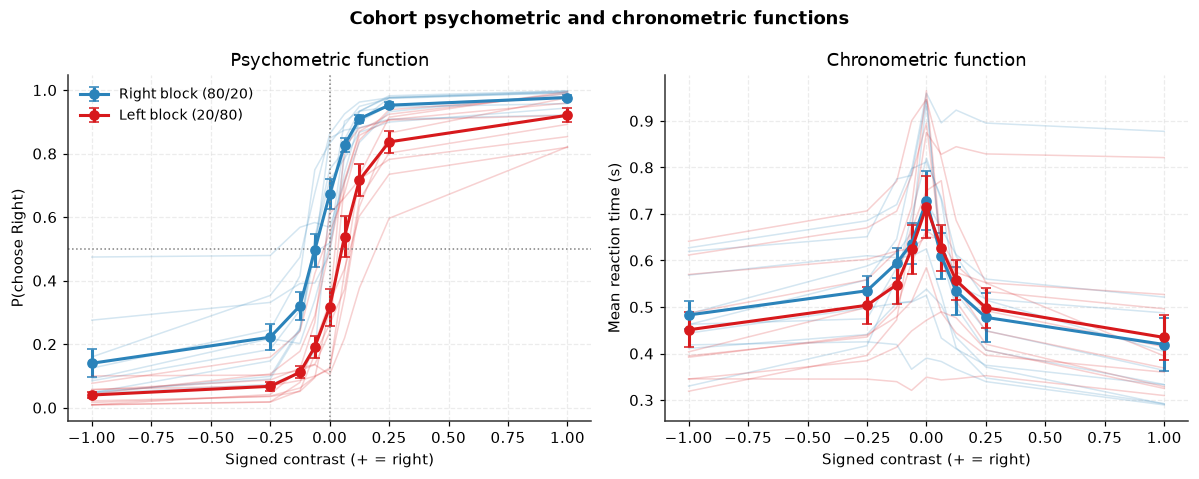

In [3]:
plot_psychometric_chronometric_cohort(df, save_path=str(FIG / "cohort_psychometric_chronometric.png"));

In [4]:
fits = fit_psychometric_by(df, n_boot=0)
fits.to_csv(TAB / "psychometric_fits.csv", index=False)
psychometric_table(df).to_csv(TAB / "psychometric_table.csv", index=False)
plot_psychometric_by_mouse(df, fits=fits, save_path=str(FIG / "psychometric_by_mouse.png"));
print("all fits converged:", bool(fits["success"].all()))
fits.round(3)

all fits converged: True


,subject_id,prior,mu,sigma,gamma,lam,nll,success,n_trials,n_contrasts
0,CSHL045,-1.0,0.065,0.073,0.007,0.116,2954.470,True,9417,9
1,CSHL045,1.0,-0.068,0.074,0.040,0.027,3178.384,True,9026,9
2,CSHL046,-1.0,-0.009,0.088,0.082,0.019,2842.809,True,5906,9
3,CSHL046,1.0,-0.108,0.077,0.121,0.012,1824.033,True,6549,9
4,CSH_ZAD_002,-1.0,-0.039,0.044,0.019,0.204,2898.103,True,7583,9
5,CSH_ZAD_002,1.0,-0.072,0.031,0.098,0.098,2565.885,True,6876,9
6,KS019,-1.0,0.088,0.036,0.070,0.034,5463.680,True,17497,9
7,KS019,1.0,0.037,0.037,0.324,0.008,6745.992,True,18475,9
8,KS021,-1.0,0.181,0.062,0.102,0.190,2471.726,True,6346,9
9,KS021,1.0,0.079,0.072,0.476,0.013,2869.580,True,6270,9


### 2.1 Prior shift
`shift = μ(left block) − μ(right block)` in contrast units: positive means the psychometric curve moves toward the block's
likelier side. Bootstrap 95% intervals resample **whole sessions** (500 resamples), because trials within a session are not independent;
the trial-level intervals are kept for comparison (`*_trial`). The per-block lapse parameters are reported too: the prior can also move
the asymptotes (γ, λ), not only the horizontal position μ.

In [5]:
ps_trial = prior_shift(df, n_boot=N_BOOT, seed=1)
ps = prior_shift(ext, n_boot=N_BOOT, seed=1, cluster_col=CL)
ps = ps.merge(ps_trial[["subject_id", "shift_lo", "shift_hi"]].rename(columns={"shift_lo": "shift_lo_trial", "shift_hi": "shift_hi_trial"}), on="subject_id")
ps.to_csv(TAB / "prior_shift.csv", index=False)
n_sig = int((ps["shift_lo"] > 0).sum())
display(Markdown(f"**{n_sig}/{len(ps)} mice** have a prior shift whose 95% interval excludes 0; all {int((ps['shift']>0).sum())} "
                 f"shifts are positive. Mean shift = {ps['shift'].mean():.3f} contrast units "
                 f"(range {ps['shift'].min():.3f}–{ps['shift'].max():.3f}); mean ΔP(Right) at 0% contrast = {ps['prior_effect_c0'].mean():.3f}."))
display(Markdown("**Block-dependent lapses** (right-block vs left-block γ and λ; a large difference means the prior moves the asymptote):"))
display(pd.concat([ps[["subject_id", "shift", "shift_lo", "shift_hi", "shift_lo_trial", "shift_hi_trial"]],
                   ps[["gamma_right_block", "gamma_left_block", "lam_right_block", "lam_left_block"]]], axis=1).round(3))

**10/10 mice** have a prior shift whose 95% interval excludes 0; all 10 shifts are positive. Mean shift = 0.080 contrast units (range 0.032–0.132); mean ΔP(Right) at 0% contrast = 0.356.

**Block-dependent lapses** (right-block vs left-block γ and λ; a large difference means the prior moves the asymptote):

,subject_id,shift,shift_lo,shift_hi,shift_lo_trial,shift_hi_trial,gamma_right_block,gamma_left_block,lam_right_block,lam_left_block
0,CSHL045,0.132,0.111,0.154,0.120,0.146,0.040,0.007,0.027,0.116
1,CSHL046,0.099,0.078,0.121,0.084,0.117,0.121,0.082,0.012,0.019
2,CSH_ZAD_002,0.032,0.021,0.048,0.021,0.042,0.098,0.019,0.098,0.204
3,KS019,0.051,0.042,0.065,0.044,0.062,0.324,0.070,0.008,0.034
4,KS021,0.102,0.069,0.135,0.057,0.127,0.476,0.102,0.013,0.190
5,NYU-01,0.094,0.072,0.119,0.079,0.109,0.043,0.007,0.075,0.207
6,NYU-09,0.034,0.027,0.041,0.029,0.038,0.067,0.034,0.051,0.085
7,ZM_1743,0.040,0.027,0.051,0.031,0.051,0.155,0.088,0.011,0.042
8,ibl_witten_07,0.109,0.088,0.131,0.096,0.123,0.189,0.058,0.012,0.046
9,ibl_witten_13,0.109,0.087,0.130,0.101,0.119,0.138,0.029,0.004,0.027


## 3. Chronometric functions
Mean RT vs signed contrast per block, per-mouse panels, RT distributions, and the correct-vs-error split
(informative for DDMs: a starting-point bias predicts *fast* errors toward the prior, a drift bias does not).

In [6]:
chrono = chronometric_table(df)
chrono.to_csv(TAB / "chronometric_table.csv", index=False)
plot_chronometric_by_mouse(df, save_path=str(FIG / "chronometric_by_mouse.png"));

In [7]:
plot_rt_distributions(df, save_path=str(FIG / "rt_distributions.png"))
rtq = rt_quantile_table(df); rtq.to_csv(TAB / "rt_quantiles_by_contrast.csv", index=False)

by_out = chronometric_table(df, by=("subject_id",), by_outcome=True)
by_out.to_csv(TAB / "chronometric_by_outcome.csv", index=False)
co = by_out.assign(abs_c=by_out.contrast.abs()).groupby(["correct", "abs_c"])["mean_rt"].mean().unstack(0)
co.columns = ["error", "correct"]; co["error − correct (s)"] = co["error"] - co["correct"]
display(Markdown("**Mean RT (s) by |contrast| and outcome (mean over mice):**"))
display(co.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
caf = accuracy_by_rt_bin(df); caf.to_csv(TAB / "conditional_accuracy.csv", index=False)
for _, g in caf.groupby("subject_id"):
    axes[0].plot(g.bin + 1, g.accuracy, color="#888", alpha=.5)
m = caf.groupby("bin")["accuracy"].mean(); axes[0].plot(m.index + 1, m.values, "k-o", lw=2)
axes[0].set(xlabel="RT quantile bin (1 = fastest)", ylabel="Accuracy (non-zero contrast)", title="Conditional accuracy function")
mc = chrono.assign(abs_c=chrono.contrast.abs()).groupby(["subject_id", "abs_c"])["mean_rt"].mean().reset_index()
for _, g in mc.groupby("subject_id"):
    axes[1].plot(g.abs_c, g.mean_rt, color="#888", alpha=.5)
mm = mc.groupby("abs_c")["mean_rt"].mean(); axes[1].plot(mm.index, mm.values, "k-o", lw=2)
axes[1].set(xlabel="|contrast|", ylabel="Mean RT (s)", title="Chronometric function vs |contrast|")
fig.tight_layout(); fig.savefig(FIG / "conditional_accuracy_and_chrono_abs.png", dpi=200, bbox_inches="tight")

**Mean RT (s) by |contrast| and outcome (mean over mice):**

,error,correct,error − correct (s)
abs_c,,,
0.0625,0.683,0.602,0.081
0.1250,0.655,0.535,0.120
0.2500,0.625,0.487,0.138
1.0000,0.489,0.438,0.051


## 4. Conditional Bias Function (CBF)
$\mathrm{CBF}(\text{bin})=P(\text{Right}\mid \text{prior Right},\text{RT bin})-P(\text{Right}\mid \text{prior Left},\text{RT bin})$ over
within-mouse **RT quintiles**. Predicted shapes: **M1 starting point → falling**, **M2 drift bias → flat**, **M3 dynamic bias → rising**.

*Design note.* In the IBL task 80% of stimuli appear on the block's likelier side, so the raw difference mixes stimulus statistics
with the mouse's bias. The CBF is therefore computed **within each signed contrast** and averaged with inverse-variance weights,
on ambiguous stimuli (|contrast| ≤ 0.125) by default. A per-mouse shape label needs the (session-level) bootstrap CI of the slope to exclude 0
**and** |slope| ≥ 0.03 per bin (calibrated so that Track A's pure drift-bias model M2, slope ≈ −0.027, is labelled flat; see §6.1).

In [8]:
curves, slopes = cbf_by_subject(ext, n_boot=N_BOOT, seed=7, cluster_col=CL)
_, slopes_trial = cbf_by_subject(df, n_boot=N_BOOT, seed=7)          # trial-level bootstrap, for comparison
curves.to_csv(TAB / "cbf_curves.csv", index=False); slopes.merge(slopes_trial[["subject_id", "slope_lo", "slope_hi", "shape"]].rename(
    columns={"slope_lo": "slope_lo_trial", "slope_hi": "slope_hi_trial", "shape": "shape_trial"}), on="subject_id").to_csv(TAB / "cbf_slopes.csv", index=False)
cohort = cohort_cbf(curves); cohort.to_csv(TAB / "cbf_cohort.csv", index=False)
test = cohort_slope_test(slopes)
pd.Series({k: v for k, v in test.items()}).to_frame("value").to_csv(TAB / "cbf_cohort_slope_test.csv")
display(Markdown(f"Per-mouse shapes with session-level bootstrap: {slopes['shape'].value_counts().to_dict()}; "
                 f"with trial-level bootstrap: {slopes_trial['shape'].value_counts().to_dict()}."))

# RT bin edges per mouse: Week 3 applies these same edges to model simulations
edges = pd.DataFrame({s: np.r_[compute_cbf(g)["rt_lo"].iloc[0], compute_cbf(g)["rt_hi"].to_numpy()]
                      for s, g in df.groupby("subject_id")}).T
edges.columns = [f"edge{i}" for i in range(edges.shape[1])]; edges.index.name = "subject_id"
edges.to_csv(TAB / "cbf_bin_edges.csv")

plot_cbf_by_mouse(curves, slopes, save_path=str(FIG / "cbf_by_mouse.png"));

Per-mouse shapes with session-level bootstrap: {'flat': 6, 'falling': 4}; with trial-level bootstrap: {'flat': 6, 'falling': 4}.

In [9]:
plot_cbf_cohort(curves, save_path=str(FIG / "cbf_cohort.png"));
display(Markdown(
    f"**Cohort CBF slope** = {test['mean_slope']:.3f} ± {test['sem_slope']:.3f} per RT bin "
    f"(t-test p = {test['t_p']:.2f}, Wilcoxon p = {test['wilcoxon_p']:.2f}); per-mouse shapes: {test['shape_counts']}."))
slopes.round(3)

**Cohort CBF slope** = -0.022 ± 0.006 per RT bin (t-test p = 0.00, Wilcoxon p = 0.01); per-mouse shapes: {'flat': 6, 'falling': 4}.

,subject_id,n_trials,slope,slope_lo,slope_hi,shape
0,CSHL045,10611,-0.040,-0.055,-0.021,falling
1,CSHL046,6830,0.008,-0.012,0.029,flat
2,CSH_ZAD_002,8226,-0.033,-0.047,-0.015,falling
3,KS019,21049,-0.038,-0.048,-0.026,falling
4,KS021,7425,-0.023,-0.047,0.003,flat
5,NYU-01,9337,-0.024,-0.051,0.000,flat
6,NYU-09,12610,0.012,0.002,0.023,flat
7,ZM_1743,8706,-0.029,-0.050,-0.011,flat
8,ibl_witten_07,23122,-0.041,-0.057,-0.022,falling
9,ibl_witten_13,23061,-0.014,-0.034,0.002,flat


### 4.1 Sensitivity to the contrast selection

In [10]:
settings = {"0% contrast only": {"max_abs_contrast": 0.0},
            "|c| ≤ 0.125 (default)": {"max_abs_contrast": 0.125},
            "all contrasts": {"max_abs_contrast": 1.0}}
plot_cbf_sensitivity(df, settings, n_boot=100, save_path=str(FIG / "cbf_sensitivity_contrast.png"));
rows = []
for label, kw in settings.items():
    _, sl = cbf_by_subject(ext, n_boot=200, seed=3, cluster_col=CL, **kw)
    t = cohort_slope_test(sl)
    rows.append({"selection": label, "mean_slope": t["mean_slope"], "sem": t["sem_slope"], "t_p": t["t_p"], **sl["shape"].value_counts().to_dict()})
sens_c = pd.DataFrame(rows).fillna(0); sens_c.to_csv(TAB / "cbf_sensitivity_contrast.csv", index=False); sens_c.round(3)

,selection,mean_slope,sem,t_p,flat,falling
0,0% contrast only,-0.031,0.010,0.011,6,4
1,|c| ≤ 0.125 (default),-0.022,0.006,0.005,6,4
2,all contrasts,-0.010,0.006,0.112,8,2


### 4.2 Sensitivity to the RT definition and to the Week 1 trial exclusion
The Week 1 cohort defined RT as first wheel movement and discarded trials below 0.1 s. Here the CBF is recomputed on the *same*
mice with (a) the response time (current definition), (b) first-movement time on every trial where it is positive, and
(c) the Week 1 definition (first movement, ≥ 0.1 s). If (c) differs from (a) and (b), the exclusion — not the RT variable — drives the difference.

In [11]:
fm = ext["rt_firstmove"]
variants = {
    "response time (current)": (ext, "rt"),
    "first movement, all positive": (ext[fm > 0], "rt_firstmove"),
    "first movement ≥ 0.1 s (Week 1)": (ext[fm >= 0.1], "rt_firstmove"),
}
rows, curves_v, slopes_v = [], {}, {}
for lab, (d, col) in variants.items():
    cu, sl = cbf_by_subject(d, n_boot=200, seed=7, rt_col=col, cluster_col=CL)
    t = cohort_slope_test(sl)
    curves_v[lab], slopes_v[lab] = cu, sl
    rows.append({"RT definition": lab, "n_trials": len(d), "mean_slope": t["mean_slope"], "sem": t["sem_slope"], "t_p": t["t_p"],
                 **sl["shape"].value_counts().to_dict()})
sens_rt = pd.DataFrame(rows).fillna(0); sens_rt.to_csv(TAB / "cbf_sensitivity_rt_definition.csv", index=False)
curves_r, slopes_r = curves_v["first movement ≥ 0.1 s (Week 1)"], slopes_v["first movement ≥ 0.1 s (Week 1)"]
curves_r.to_csv(TAB / "cbf_curves_firstmove_week1.csv", index=False); slopes_r.to_csv(TAB / "cbf_slopes_firstmove_week1.csv", index=False)
fig, ax = plt.subplots(figsize=(6.4, 4.2))
for (lab, cur), col in zip(curves_v.items(), ("#111111", "#2ca02c", "#d62728")):
    c = cohort_cbf(cur); ax.errorbar(c.bin + 1, c.cbf, yerr=c["sem"], marker="o", lw=2, capsize=3, color=col, label=lab)
ax.axhline(0, color="gray", ls=":"); ax.set(xlabel="RT quantile bin (1 = fastest)", ylabel="ΔP(Right | prior)", title="Cohort CBF under three RT definitions")
ax.legend(frameon=False, fontsize=8); fig.tight_layout(); fig.savefig(FIG / "cbf_sensitivity_rt_definition.png", dpi=200)

# Are the trials with anticipatory first movement (< 0.1 s) a random subset?  Compare how often the choice follows the block.
follows = (ext["choice"] == ext["prior"])
early = fm < 0.1
sel = pd.Series({"P(choice follows block), first movement < 0.1 s": follows[early].mean(),
                 "P(choice follows block), first movement ≥ 0.1 s": follows[fm >= 0.1].mean(),
                 "fraction of trials with first movement < 0.1 s or missing": float((early | fm.isna()).mean())}).round(3)
display(Markdown("**The Week 1 exclusion removed a non-random subset:**")); display(sel.to_frame("value"))
t_r = cohort_slope_test(slopes_r)
sens_rt.round(3)

**The Week 1 exclusion removed a non-random subset:**

,value
"P(choice follows block), first movement < 0.1 s",0.802
"P(choice follows block), first movement ≥ 0.1 s",0.758
fraction of trials with first movement < 0.1 s or missing,0.571


,RT definition,n_trials,mean_slope,sem,t_p,flat,falling,rising
0,response time (current),229140,-0.022,0.006,0.005,6,4,0.0
1,"first movement, all positive",187450,-0.016,0.007,0.062,7,3,0.0
2,first movement ≥ 0.1 s (Week 1),98279,-0.001,0.012,0.911,6,2,2.0


### 4.3 Robustness: block position and leaving out KS021
The CBF uses the block label as the prior, but the mouse needs some trials to infer a new block. Dropping the first *n* trials of each block
checks that early, mislabelled trials do not drive the result. KS021 is the weakest mouse (large lapses); the second table repeats the cohort test without it.

In [12]:
rows = []
for n0 in (0, 10, 20, 40):
    d = ext[ext["block_pos"] >= n0]
    _, sl = cbf_by_subject(d, n_boot=200, seed=5, cluster_col=CL)
    t = cohort_slope_test(sl)
    rows.append({"skip first n trials of each block": n0, "n_trials": len(d), "mean_slope": t["mean_slope"], "sem": t["sem_slope"], "t_p": t["t_p"],
                 **sl["shape"].value_counts().to_dict()})
sens_blk = pd.DataFrame(rows).fillna(0); sens_blk.to_csv(TAB / "cbf_sensitivity_block_position.csv", index=False)
loo = []
for lab, ex in (("all 10 mice", []), ("without KS021", ["KS021"])):
    t = cohort_slope_test(slopes, exclude=ex); k = ps[~ps.subject_id.isin(ex)]
    loo.append({"cohort": lab, "n_mice": t["n_mice"], "mean_cbf_slope": t["mean_slope"], "sem": t["sem_slope"], "t_p": t["t_p"],
                "mean_prior_shift": k["shift"].mean(), "mean_dP_c0": k["prior_effect_c0"].mean()})
loo = pd.DataFrame(loo); loo.to_csv(TAB / "robustness_without_ks021.csv", index=False)
display(sens_blk.round(3)); loo.round(3)

,skip first n trials of each block,n_trials,mean_slope,sem,t_p,flat,falling
0,0,229140,-0.022,0.006,0.005,6,4
1,10,182901,-0.028,0.008,0.005,3,7
2,20,137273,-0.032,0.008,0.003,3,7
3,40,66645,-0.033,0.009,0.007,5,5


,cohort,n_mice,mean_cbf_slope,sem,t_p,mean_prior_shift,mean_dP_c0
0,all 10 mice,10,-0.022,0.006,0.005,0.080,0.356
1,without KS021,9,-0.022,0.007,0.011,0.078,0.344


## 5. Individual-mouse heterogeneity
One row of behavioural metrics per mouse: sensitivity (σ, lapses, accuracy), prior use (shift, ΔP at 0% contrast, prior effect on each lapse),
choice history (the history effect is estimated *within* each block so it cannot be confounded with the block prior),
speed (RT median/IQR/q90, fraction slow, chronometric slope) and the CBF slope. Outliers use a robust z-score (median/MAD) > 2.

In [13]:
prof = mouse_profile(ext, n_boot=N_BOOT, seed=11, shifts=ps, slopes=slopes)
prof.to_csv(TAB / "mouse_profile.csv", index=False)
hsum = heterogeneity_summary(prof); hsum.to_csv(TAB / "heterogeneity_summary.csv", index=False)
corr = profile_correlations(prof); corr.to_csv(TAB / "profile_correlations.csv")
plot_heterogeneity(prof, save_path=str(FIG / "heterogeneity.png"));
hsum.round(3)

,metric,mean,sd,cv,min,max,outliers
0,sigma,0.057,0.019,0.344,0.028,0.083,
1,gamma,0.107,0.083,0.769,0.024,0.289,KS021
2,lam,0.064,0.052,0.808,0.015,0.151,"CSH_ZAD_002, NYU-01"
3,easy_accuracy,0.936,0.026,0.028,0.869,0.962,KS021
4,hard_accuracy,0.812,0.048,0.059,0.734,0.909,"KS021, NYU-09"
5,prior_shift,0.080,0.037,0.460,0.032,0.132,
6,prior_effect_c0,0.356,0.081,0.227,0.237,0.488,
7,gamma_block_diff,0.115,0.113,0.983,0.033,0.374,"KS019, KS021"
8,lam_block_diff,-0.066,0.057,0.862,-0.176,-0.007,"CSH_ZAD_002, KS021, NYU-01"
9,repeat_rate,0.701,0.031,0.044,0.655,0.762,"CSH_ZAD_002, KS021"


In [14]:
fig, ax = plt.subplots(figsize=(7.2, 6))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index, fontsize=8)
fig.colorbar(im, label="Spearman ρ (n = 10 mice)"); ax.set_title("Between-mouse metric correlations")
fig.tight_layout(); fig.savefig(FIG / "profile_correlations.png", dpi=200)
strong = (corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().loc[lambda s: s.abs() > 0.7].sort_values())
display(Markdown("**Strongest between-mouse correlations (|ρ| > 0.7; descriptive, n = 10, no multiple-comparison correction):**"))
strong.round(2).to_frame("rho")

**Strongest between-mouse correlations (|ρ| > 0.7; descriptive, n = 10, no multiple-comparison correction):**

rho
lam              lam_block_diff    -0.94
repeat_rate      rt_median         -0.87
prior_effect_c0  rt_median         -0.81
                 rt_iqr            -0.79
                 frac_slow         -0.79
                 rt_q90            -0.79
repeat_rate      rt_iqr            -0.78
                 rt_q90            -0.78
                 frac_slow         -0.78
rt_iqr           chrono_slope      -0.72
frac_slow        chrono_slope      -0.72
rt_q90           chrono_slope      -0.72
repeat_rate      history_effect_c0  0.73
prior_shift      prior_effect_c0    0.75
                 repeat_rate        0.76
gamma_block_diff chrono_slope       0.82
gamma            gamma_block_diff   0.89
prior_effect_c0  repeat_rate        0.92
rt_median        rt_iqr             0.94
                 rt_q90             0.94
                 frac_slow          0.94
rt_iqr           rt_q90             1.00
                 frac_slow          1.00
rt_q90           frac_slow          1.00

In [15]:
prof[["subject_id", "n_trials", "sigma", "gamma", "lam", "gamma_block_diff", "lam_block_diff", "prior_shift", "prior_effect_c0",
      "history_effect_c0", "rt_median", "rt_q90", "frac_slow", "cbf_slope", "cbf_shape"]].round(3)

,subject_id,n_trials,sigma,gamma,lam,gamma_block_diff,lam_block_diff,prior_shift,prior_effect_c0,history_effect_c0,rt_median,rt_q90,frac_slow,cbf_slope,cbf_shape
0,CSHL045,18443,0.074,0.024,0.071,0.033,-0.088,0.132,0.488,0.363,0.378,1.144,0.121,-0.040,falling
1,CSHL046,12455,0.083,0.102,0.015,0.039,-0.007,0.099,0.281,0.275,0.485,1.558,0.196,0.008,flat
2,CSH_ZAD_002,14459,0.038,0.059,0.151,0.079,-0.106,0.032,0.237,0.188,0.484,1.771,0.227,-0.033,falling
3,KS019,35972,0.036,0.197,0.021,0.254,-0.026,0.051,0.362,0.278,0.403,0.931,0.087,-0.038,falling
4,KS021,12616,0.067,0.289,0.101,0.374,-0.176,0.102,0.463,0.355,0.284,0.534,0.021,-0.023,flat
5,NYU-01,17489,0.071,0.025,0.141,0.036,-0.133,0.094,0.384,0.423,0.386,1.161,0.122,-0.024,flat
6,NYU-09,22293,0.028,0.050,0.068,0.033,-0.034,0.034,0.314,0.284,0.462,1.269,0.144,0.012,flat
7,ZM_1743,15528,0.038,0.122,0.026,0.067,-0.031,0.040,0.278,0.342,0.443,1.364,0.163,-0.029,flat
8,ibl_witten_07,40268,0.069,0.124,0.029,0.131,-0.034,0.109,0.361,0.248,0.330,0.737,0.067,-0.041,falling
9,ibl_witten_13,39617,0.064,0.083,0.016,0.109,-0.022,0.109,0.393,0.326,0.317,0.677,0.053,-0.014,flat


## 6. Tool validation on synthetic mock data (plan §4, Week 2 task 4)
`src.empirical.mock` generates §3.1 tables with **known** psychometric parameters, prior strength and RT-dependence of the bias —
independently of Track A's simulator. The tools must recover the truth. The automated version of these checks lives in
`tests/test_empirical.py` (`pytest tests/test_empirical.py`), which also feeds the tools shuffled / extra-column / categorical
variants, single-block tables, Track A simulator output and the real cohort, and checks they reject schema-violating tables.

In [16]:
mc = make_mock_cohort(n_subjects=8, n_trials=10000, seed=21)
truth = mc.attrs["truth"].set_index("subject_id")
mfit = fit_psychometric_by(mc).groupby("subject_id")[["sigma", "gamma", "lam"]].mean()
mps = prior_shift(mc, n_boot=100).set_index("subject_id")
rec = pd.DataFrame({"sigma_true": truth.sigma, "sigma_fit": mfit.sigma,
                    "lapse_L_true": truth.gamma, "lapse_L_fit": mfit.gamma,
                    "lapse_R_true": truth.lam, "lapse_R_fit": mfit.lam,
                    "shift_true": truth["shift"], "shift_fit": mps["shift"]})
rec.to_csv(TAB / "mock_recovery.csv")
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, (a, b, name) in zip(axes, [("sigma_true", "sigma_fit", "σ"), ("lapse_L_true", "lapse_L_fit", "γ (P(R), far left)"),
                                   ("lapse_R_true", "lapse_R_fit", "λ (P(L), far right)"), ("shift_true", "shift_fit", "prior shift")]):
    ax.scatter(rec[a], rec[b], color="k"); lim = [min(rec[a].min(), rec[b].min()), max(rec[a].max(), rec[b].max())]
    ax.plot(lim, lim, "r--"); ax.set(xlabel="true", ylabel="recovered", title=f"{name}  (r = {np.corrcoef(rec[a], rec[b])[0,1]:.2f})")
fig.tight_layout(); fig.savefig(FIG / "mock_parameter_recovery.png", dpi=200)

In [17]:
rows, curves_m = [], {}
for shape in ("falling", "flat", "rising"):
    m = make_mock_trials(20000, cbf_shape=shape, seed=1)
    b = bootstrap_cbf(m, n_boot=300, seed=2)
    rows.append({"true_shape": shape, "recovered_shape": b["shape"], "slope": b["slope"], "slope_lo": b["slope_lo"], "slope_hi": b["slope_hi"]})
    curves_m[f"mock: {shape}"] = (compute_cbf(m)["rt_median"].to_numpy(), b["cbf"])
shape_tab = pd.DataFrame(rows); shape_tab.to_csv(TAB / "mock_cbf_shape_recovery.csv", index=False)
print("CBF shape recovered for all 3 mock shapes:", bool((shape_tab.true_shape == shape_tab.recovered_shape).all()))
shape_tab.round(3)

CBF shape recovered for all 3 mock shapes: True


,true_shape,recovered_shape,slope,slope_lo,slope_hi
0,falling,falling,-0.114,-0.126,-0.100
1,flat,flat,-0.007,-0.021,0.008
2,rising,rising,0.101,0.089,0.114


### 6.1 Cross-track check: the same tools on Track A's simulator
Qualitative reference only (default demo parameters from `run_track_a.py`, **not** fitted to the mice): the CBF tool should label the
M1 / M2 / M3 simulations falling / flat / rising. This is the contract that Week 3 relies on.

In [18]:
cfg = {"M1 (starting point)": ("M1", {"a": 1.1, "t0": 0.2, "k": 2.6, "z": 0.40}),
       "M2 (drift bias)": ("M2", {"a": 1.1, "t0": 0.2, "k": 2.6, "v_b": 0.55}),
       "M3 (dynamic bias)": ("M3", {"a": 1.1, "t0": 0.2, "k": 2.6, "b_max": 1.2, "tau_b": 0.5})}
rows, ref = [], {}
for label, (mt, p) in cfg.items():
    sim = simulate_ddm(p, model_type=mt, n_trials=20000, seed=101)
    b = bootstrap_cbf(sim, n_boot=200, seed=0)
    rows.append({"model": label, "slope": b["slope"], "slope_lo": b["slope_lo"], "slope_hi": b["slope_hi"], "shape": b["shape"]})
    ref[label] = b["cbf"]
ref_tab = pd.DataFrame(rows); ref_tab.to_csv(TAB / "track_a_reference_cbf.csv", index=False)
plot_cbf_cohort(curves, overlay=ref, save_path=str(FIG / "cbf_cohort_with_reference_models.png"),
                title="Empirical CBF vs qualitative M1/M2/M3 reference (unfitted)");
ref_tab.round(3)

,model,slope,slope_lo,slope_hi,shape
0,M1 (starting point),-0.249,-0.261,-0.236,falling
1,M2 (drift bias),-0.027,-0.041,-0.010,flat
2,M3 (dynamic bias),0.088,0.072,0.104,rising


## 7. Summary

In [19]:
t = cohort_slope_test(slopes)
msg = f'''
**Data.** {len(df):,} trials from {df.subject_id.nunique()} mice (RT = response time); median RT {df.rt.median():.2f} s
(per-mouse medians {prof.rt_median.min():.2f}–{prof.rt_median.max():.2f} s).

**Psychometrics.** Prior shift positive in {int((ps['shift']>0).sum())}/{len(ps)} mice; {n_sig}/{len(ps)} have a session-level 95% interval excluding 0
(trial-level: {int((ps['shift_lo_trial']>0).sum())}/{len(ps)}). Mean shift {ps['shift'].mean():.3f} contrast units, mean ΔP(Right) at 0% contrast {ps['prior_effect_c0'].mean():.2f}.
Slope scale σ varies {prof.sigma.min():.3f}–{prof.sigma.max():.3f}; γ {prof.gamma.min():.2f}–{prof.gamma.max():.2f}.
The prior also changes the lapse asymptotes in some mice (γ right − left block: {prof.gamma_block_diff.min():+.2f} to {prof.gamma_block_diff.max():+.2f}).

**Chronometrics.** Mean RT falls from {mm.loc[0.0]:.2f} s (0% contrast) to {mm.loc[1.0]:.2f} s (100%).

**CBF.** Default selection (|contrast| ≤ 0.125, session-level bootstrap): cohort slope {t['mean_slope']:.3f} ± {t['sem_slope']:.3f} per RT bin (p = {t['t_p']:.3f}); per-mouse shapes {t['shape_counts']}.
By contrast selection: {"; ".join(f"{r.selection}: {r.mean_slope:+.3f} (p = {r.t_p:.3f})" for r in sens_c.itertuples())}.
By RT definition: {"; ".join(f"{r._1}: {r.mean_slope:+.3f} (p = {r.t_p:.3f})" for r in sens_rt.itertuples())}.
By block position (skip first n trials): {"; ".join(f"n={r._1}: {r.mean_slope:+.3f}" for r in sens_blk.itertuples())}.
Without KS021: slope {loo.mean_cbf_slope[1]:+.3f} (p = {loo.t_p[1]:.3f}).

**Heterogeneity.** Outliers: {"; ".join(f"{r.metric}: {r.outliers}" for r in hsum.itertuples() if r.outliers) or "none"}.

**Handoff to Week 3.** `results/empirical/cbf_bin_edges.csv` holds each mouse's RT quintile edges; pass them as `bin_edges` to
`compute_cbf` so model simulations are binned identically, and pass per-bin model CBFs to `plot_cbf_cohort(..., overlay=...)`.
'''
display(Markdown(msg))


**Data.** 229,140 trials from 10 mice (RT = response time); median RT 0.37 s
(per-mouse medians 0.28–0.49 s).

**Psychometrics.** Prior shift positive in 10/10 mice; 10/10 have a session-level 95% interval excluding 0
(trial-level: 10/10). Mean shift 0.080 contrast units, mean ΔP(Right) at 0% contrast 0.36.
Slope scale σ varies 0.028–0.083; γ 0.02–0.29.
The prior also changes the lapse asymptotes in some mice (γ right − left block: +0.03 to +0.37).

**Chronometrics.** Mean RT falls from 0.72 s (0% contrast) to 0.45 s (100%).

**CBF.** Default selection (|contrast| ≤ 0.125, session-level bootstrap): cohort slope -0.022 ± 0.006 per RT bin (p = 0.005); per-mouse shapes {'flat': 6, 'falling': 4}.
By contrast selection: 0% contrast only: -0.031 (p = 0.011); |c| ≤ 0.125 (default): -0.022 (p = 0.005); all contrasts: -0.010 (p = 0.112).
By RT definition: response time (current): -0.022 (p = 0.005); first movement, all positive: -0.016 (p = 0.062); first movement ≥ 0.1 s (Week 1): -0.001 (p = 0.911).
By block position (skip first n trials): n=0: -0.022; n=10: -0.028; n=20: -0.032; n=40: -0.033.
Without KS021: slope -0.022 (p = 0.011).

**Heterogeneity.** Outliers: gamma: KS021; lam: CSH_ZAD_002, NYU-01; easy_accuracy: KS021; hard_accuracy: KS021, NYU-09; gamma_block_diff: KS019, KS021; lam_block_diff: CSH_ZAD_002, KS021, NYU-01; repeat_rate: CSH_ZAD_002, KS021; cbf_slope: NYU-09.

**Handoff to Week 3.** `results/empirical/cbf_bin_edges.csv` holds each mouse's RT quintile edges; pass them as `bin_edges` to
`compute_cbf` so model simulations are binned identically, and pass per-bin model CBFs to `plot_cbf_cohort(..., overlay=...)`.
